In [1]:
import matplotlib.pyplot as plt
import numpy as np
from spanks.synthetic_sky import get_synthetic_sky_image
from spanks.noise_suppressor2D import suppress_noise2d
from astropy.convolution import Gaussian2DKernel
from scipy.signal import convolve2d

# 1. Making a synthetic sky image for the test
image_size = (1000, 1000)
noise_std = 0.5
symmetric = False

number_of_psf_sources = 40
psf_std_range = (3, 10)
psf_dynamic_range = (2.5, 5)

number_of_sersic_sources = 8
r_eff_range = (100, 150)
n_range = (1.5, 4.5)
ellip_range = (0, 0.8)
theta_range = (0, np.pi)
sersic_dynamic_range = (2, 4.5)
np.random.seed(42) # Change to generate a different sky
gradient_level = 0.0
gradient_slope = 0

sky_image = get_synthetic_sky_image(image_size, noise_std, number_of_psf_sources, psf_std_range, psf_dynamic_range, number_of_sersic_sources, r_eff_range, n_range, ellip_range, theta_range, sersic_dynamic_range, gradient_level, gradient_slope, symmetric)

sky_image_flat_bkg = sky_image # In case next step is omitted

In [2]:
"""This step is optional but recommended if image has a non-constant background"""
# 2. Subtracting background gradient
from photutils.segmentation import detect_threshold, detect_sources
from photutils.background import Background2D, SExtractorBackground, MADStdBackgroundRMS

# 2.1 Detecting all sources in image to mask from background
src_detection_kernel = Gaussian2DKernel(2.0)
image_convolved = convolve2d(sky_image, src_detection_kernel, mode='same', boundary='symm')
det_threshold = detect_threshold(image_convolved, n_sigma = 5)
seg_map = detect_sources(image_convolved, det_threshold, n_pixels = 10, connectivity=8)
sources_mask = seg_map.make_source_mask(size=1)

# 2.2 Estimating background
bkg = Background2D(sky_image, box_size=(16, 16), mask=sources_mask, filter_size = (5,5), exclude_percentile=5,
                   bkg_estimator=SExtractorBackground(), bkg_rms_estimator=MADStdBackgroundRMS())
bkg_image = bkg.background
sky_image_flat_bkg = sky_image - bkg_image


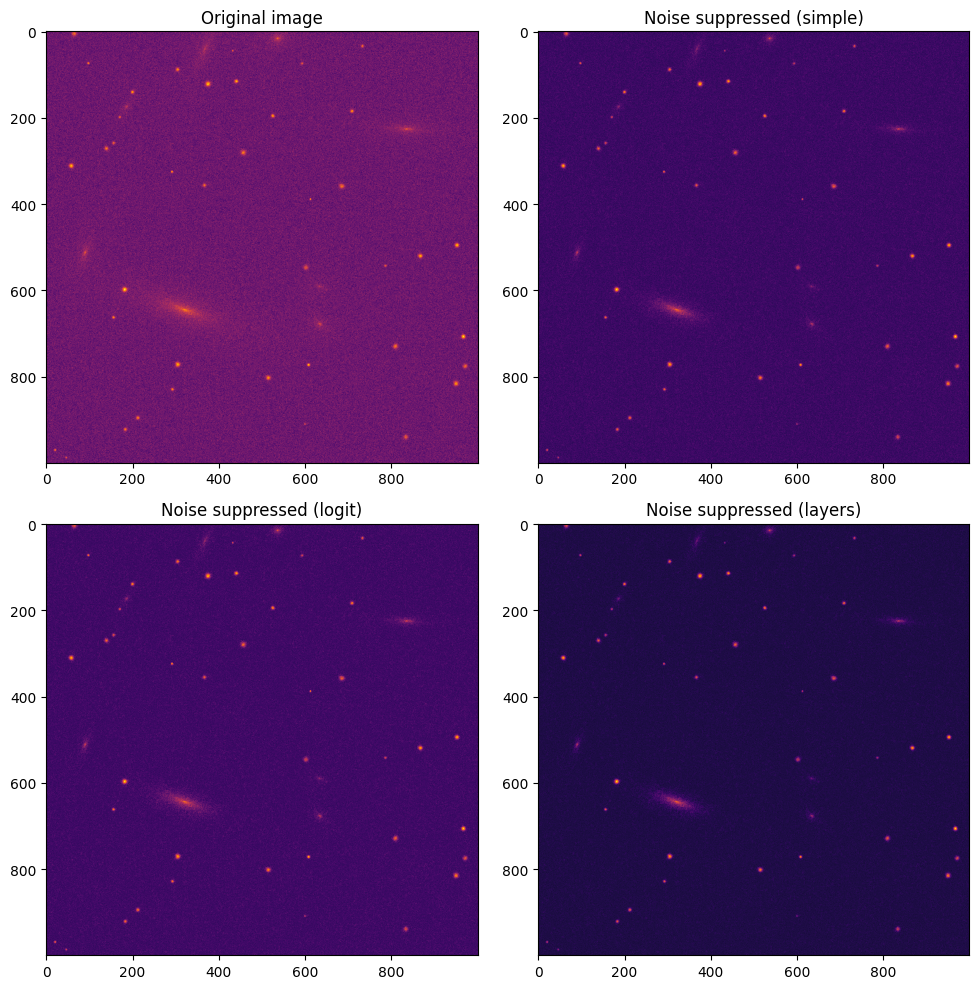

In [3]:
# 3. Suppressing image noise with different methods
sky_image_sup_simple = suppress_noise2d(sky_image_flat_bkg, method="simple", symmetric = symmetric)
sky_image_sup_logit = suppress_noise2d(sky_image_flat_bkg, method="logit", symmetric = symmetric)
sky_image_sup_layers = suppress_noise2d(sky_image_flat_bkg, method="layers", symmetric = symmetric)

cmap = "inferno"
# 4. Plotting results
fig, ax = plt.subplots(2,2, figsize = (10,10))
ax[0,0].imshow(sky_image, cmap = cmap)
ax[0,0].set_title("Original image")
ax[0,1].imshow(sky_image_sup_simple, cmap = cmap)
ax[0,1].set_title("Noise suppressed (simple)")
ax[1,0].imshow(sky_image_sup_logit, cmap = cmap)
ax[1,0].set_title("Noise suppressed (logit)")
ax[1,1].imshow(sky_image_sup_layers, cmap = cmap)
ax[1,1].set_title("Noise suppressed (layers)")
plt.tight_layout()
plt.show()
